# Tokke–Vinje Unit Commitment — Exploratory Data Analysis

**Task.** Predict, for each of the 14 generating units in the Tokke–Vinje hydropower system, the
probability that the unit is ON at every hour of a 168-hour (1-week) rolling scheduling horizon.
Ground truth comes from a SHOP optimization run (`Unit_commitment_decisions.csv`). Submissions are
scored on Kaggle with **micro-average ROC-AUC**.

**Train / test split.** The full problem spans 3,647 daily rolling cases (2015-01-01 → 2024-12-25).
We only have labels for the first **2,922 cases (2015-01-01 → 2022-12-31)** — that's `Unit_commitment_decisions.csv`.
The remaining **725 cases (2023-01-01 → 2024-12-25)**, listed in `prediction_mapping.csv`, are the
Kaggle test set we must predict for.

This notebook builds a first overview of the data, then digs for signal that can inform feature
engineering and modeling choices.


In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

DATA = "../../data"

# --- dataviz palette (see project dataviz skill / references/palette.md) ---
INK = "#0b0b0b"
INK_SECONDARY = "#52514e"
INK_MUTED = "#898781"
GRID = "#e1e0d9"
BASELINE = "#c3c2b7"
SURFACE = "#fcfcfb"

CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
SEQ_BLUE = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#2a78d6", "#1c5cab", "#104281"]
DIVERGE = ("#2a78d6", "#f0efec", "#e34948")  # blue -> neutral -> red

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": BASELINE,
    "axes.labelcolor": INK_SECONDARY,
    "axes.titlecolor": INK,
    "text.color": INK,
    "xtick.color": INK_MUTED,
    "ytick.color": INK_MUTED,
    "grid.color": GRID,
    "axes.grid": True,
    "grid.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
    "figure.dpi": 110,
})

pd.set_option("display.max_columns", 20)


## 1. Load everything and get the lay of the land

In [2]:
paths = {
    "price":      f"{DATA}/kernel/Historical_day_ahead_price_2015_2025.csv",
    "inflow":     f"{DATA}/kernel/Historical_inflow_1958_2025.csv",
    "volume":     f"{DATA}/kernel/Historical_volume_2015_2024.csv",
    "water_value":f"{DATA}/kernel/Synthetic_water_value_2015_2024.csv",
    "uc":         f"{DATA}/kernel/Unit_commitment_decisions.csv",
    "min_volume": f"{DATA}/extended/Constraint_min_volume.csv",
    "min_flow":   f"{DATA}/extended/Constraint_min_flow.csv",
}

price = pd.read_csv(paths["price"])
inflow = pd.read_csv(paths["inflow"])
volume = pd.read_csv(paths["volume"])
water_value = pd.read_csv(paths["water_value"])
uc = pd.read_csv(paths["uc"])
min_volume = pd.read_csv(paths["min_volume"])
min_flow = pd.read_csv(paths["min_flow"])

pred_mapping = pd.read_csv("../../prediction_mapping.csv")
sample_sub = pd.read_csv("../../sample_submission.csv", nrows=1)

for name, df in [("price", price), ("inflow", inflow), ("volume", volume),
                  ("water_value", water_value), ("uc", uc),
                  ("min_volume", min_volume), ("min_flow", min_flow),
                  ("prediction_mapping", pred_mapping)]:
    print(f"{name:20s} shape={df.shape}")


price                shape=(103062, 2)
inflow               shape=(594224, 19)
volume               shape=(3654, 18)
water_value          shape=(3654, 18)
uc                   shape=(2922, 2355)
min_volume           shape=(96432, 4)
min_flow             shape=(96432, 7)
prediction_mapping   shape=(725, 2)


In [3]:
# Normalize date columns to tz-naive datetimes
for df, col in [(price, "date"), (inflow, "date"), (volume, "date"), (water_value, "date"),
                 (min_volume, "date"), (min_flow, "date")]:
    df[col] = pd.to_datetime(df[col]).dt.tz_localize(None)
uc["starttime"] = pd.to_datetime(uc["starttime"])
pred_mapping["starttime"] = pd.to_datetime(pred_mapping["starttime"])

overview = pd.DataFrame([
    ("price",       price["date"].min(),       price["date"].max(),       "hourly (15-min from 2025)"),
    ("inflow",      inflow["date"].min(),      inflow["date"].max(),      "hourly"),
    ("volume",      volume["date"].min(),      volume["date"].max(),      "daily"),
    ("water_value", water_value["date"].min(), water_value["date"].max(), "daily"),
    ("min_volume",  min_volume["date"].min(),  min_volume["date"].max(),  "hourly"),
    ("min_flow",    min_flow["date"].min(),    min_flow["date"].max(),    "hourly"),
    ("uc (train labels)", uc["starttime"].min(), uc["starttime"].max(),   "daily case start, 168h horizon"),
    ("prediction_mapping (test)", pred_mapping["starttime"].min(), pred_mapping["starttime"].max(), "daily case start"),
], columns=["dataset", "start", "end", "resolution"])
overview


,dataset,start,end,resolution
0,price,2015-01-01,2025-12-31 23:45:00,hourly (15-min from 2025)
1,inflow,1958-01-01,2025-10-15 07:00:00,hourly
2,volume,2015-01-01,2025-01-01 00:00:00,daily
3,water_value,2015-01-01,2025-01-01 00:00:00,daily
4,min_volume,2015-01-01,2025-12-31 23:00:00,hourly
5,min_flow,2015-01-01,2025-12-31 23:00:00,hourly
6,uc (train labels),2015-01-01,2022-12-31 00:00:00,"daily case start, 168h horizon"
7,prediction_mapping (test),2023-01-01,2024-12-25 00:00:00,daily case start


**Takeaways so far**

- `price`, `inflow`, `min_volume`, `min_flow` run hourly through 2024 and beyond (price switches to
  15-min resolution starting 2025, outside our range of interest).
- `volume` and `water_value` are **daily** snapshots (value at the *start* of each day).
- `uc` (our labels) covers exactly the train window; `prediction_mapping` covers exactly the test
  window with no gap or overlap (2,922 + 725 = 3,647, matching the task PDF's total case count).
- No missing values were found in any of the core files (checked below).


In [4]:
na_counts = {name: df.isna().sum().sum() for name, df in
             [("price", price), ("inflow", inflow), ("volume", volume),
              ("water_value", water_value), ("uc", uc),
              ("min_volume", min_volume), ("min_flow", min_flow)]}
na_counts


{'price': np.int64(0),
 'inflow': np.int64(0),
 'volume': np.int64(0),
 'water_value': np.int64(0),
 'uc': np.int64(0),
 'min_volume': np.int64(0),
 'min_flow': np.int64(0)}

## 2. The target: unit commitment decisions

Each case has 14 units × 168 hours = 2,352 binary label columns, named
`result_committed_<Plant>_<Unit>_t<hour>`. `total_calculation_time` (SHOP solver runtime) is also
present in the training file — **it's solver metadata, not a usable feature**: it won't exist for
the test cases we need to predict, so using it anywhere in a feature pipeline would be leakage.


In [5]:
label_cols = [c for c in uc.columns if c.startswith("result_committed_")]
units = sorted({re.match(r"result_committed_(.+)_t\d+$", c).group(1) for c in label_cols})
print(f"{len(units)} units:", units)
print(f"{len(label_cols)} label columns, overall ON rate = {uc[label_cols].to_numpy().mean():.3f}")


14 units: ['Byrte_G1', 'Haukeli_G1', 'Hogga_G1', 'Kjela_G1', 'Lio_G1', 'Songa_G1', 'Tokke_G1', 'Tokke_G2', 'Tokke_G3', 'Tokke_G4', 'Vesle Kjela_G1', 'Vinje_G1', 'Vinje_G2', 'Vinje_G3']
2352 label columns, overall ON rate = 0.516


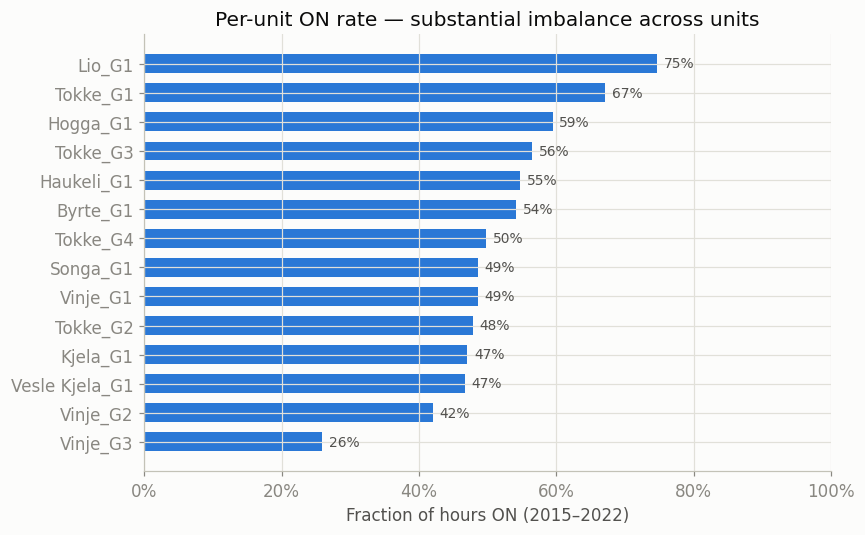

In [6]:
def unit_cols(u):
    return [f"result_committed_{u}_t{t}" for t in range(168)]

unit_rate = pd.Series({u: uc[unit_cols(u)].to_numpy().mean() for u in units}).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(unit_rate.index[::-1], unit_rate.values[::-1], color=CAT[0], height=0.65)
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
ax.set_xlabel("Fraction of hours ON (2015–2022)")
ax.set_title("Per-unit ON rate — substantial imbalance across units")
for y, v in enumerate(unit_rate.values[::-1]):
    ax.text(v + 0.01, y, f"{v:.0%}", va="center", color=INK_SECONDARY, fontsize=9)
plt.tight_layout()
plt.show()


**Insight — per-unit class imbalance.** ON rates range from **26% (Vinje_G3)** to **75% (Lio_G1)**.
This isn't a single balanced binary problem; a model (or threshold) tuned globally will likely
under-serve the extreme units. Worth tracking per-unit AUC during validation, not just the pooled
micro-average the leaderboard reports.


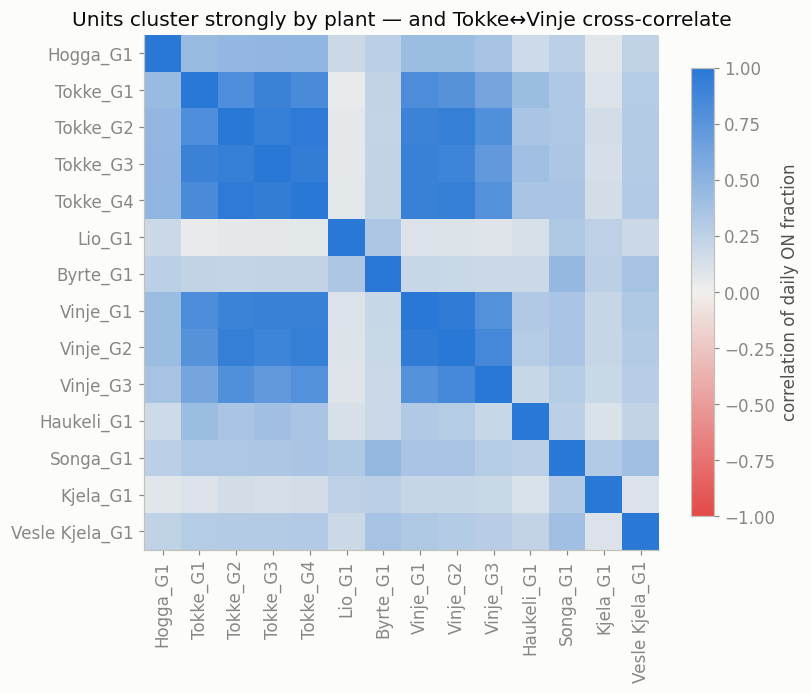

In [7]:
# Correlation between units' daily ON fraction, ordered by plant so plant clusters are visible
plant_order = ["Hogga_G1",
               "Tokke_G1","Tokke_G2","Tokke_G3","Tokke_G4",
               "Lio_G1","Byrte_G1",
               "Vinje_G1","Vinje_G2","Vinje_G3","Haukeli_G1",
               "Songa_G1","Kjela_G1","Vesle Kjela_G1"]

unit_daily = pd.DataFrame({u: uc[unit_cols(u)].mean(axis=1) for u in plant_order})
corr = unit_daily.corr()

fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(corr.values, cmap="RdBu_r" if False else None, vmin=-1, vmax=1)
# custom blue<->red diverging colormap consistent with the palette
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("diverge", [DIVERGE[2], DIVERGE[1], DIVERGE[0]])
im.set_cmap(cmap)
ax.set_xticks(range(len(plant_order)), plant_order, rotation=90)
ax.set_yticks(range(len(plant_order)), plant_order)
ax.grid(False)
cbar = fig.colorbar(im, ax=ax, shrink=0.8)
cbar.set_label("correlation of daily ON fraction")
ax.set_title("Units cluster strongly by plant — and Tokke↔Vinje cross-correlate")
plt.tight_layout()
plt.show()


**Insight — strong cross-unit structure.** Units at the same plant move almost in lockstep
(Tokke's 4 units: 0.8–0.93 pairwise correlation; Vinje's 3 units: 0.78–0.96). More surprisingly,
**Tokke and Vinje — two different plants on different reservoirs — are also strongly correlated
(~0.8–0.9)**, likely because both respond to the same system-wide price/scarcity signal. This
argues for a model that shares information across units (multi-task / multi-label output, or
plant-level features) rather than 14 independent per-unit models — and suggests post-processing
(e.g. calibrating predictions jointly) could help since the labels are far from independent.


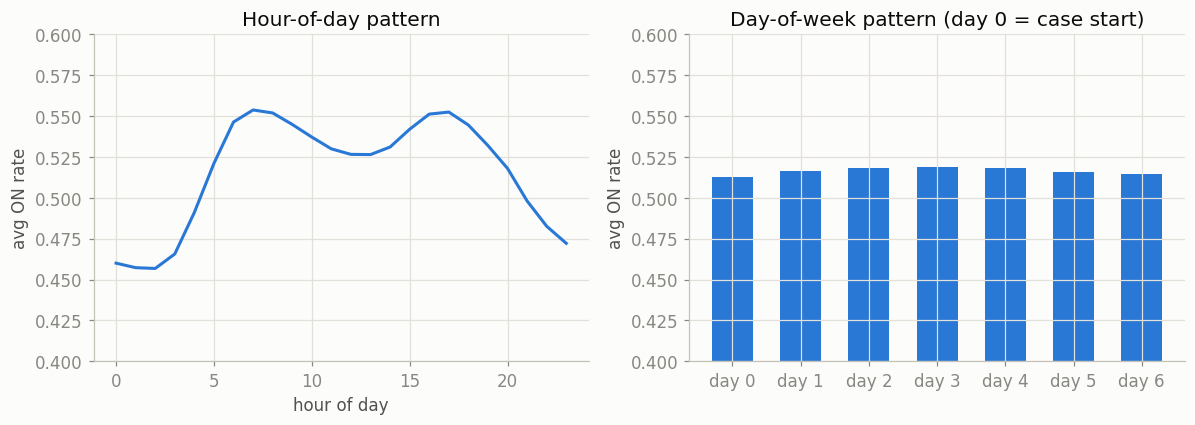

In [8]:
# Hour-of-day / day-of-week pattern, pooled across all units and cases
all_t = np.array([uc[[f"result_committed_{u}_t{t}" for u in units]].to_numpy().mean() for t in range(168)])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

hod = pd.Series(all_t).groupby(np.arange(168) % 24).mean()
axes[0].plot(hod.index, hod.values, color=CAT[0], lw=2)
axes[0].set_xlabel("hour of day")
axes[0].set_ylabel("avg ON rate")
axes[0].set_title("Hour-of-day pattern")
axes[0].set_ylim(0.40, 0.60)

dow = pd.Series(all_t).groupby(np.arange(168) // 24).mean()
axes[1].bar(range(7), dow.values, color=CAT[0], width=0.6)
axes[1].set_xticks(range(7), ["day " + str(i) for i in range(7)])
axes[1].set_ylabel("avg ON rate")
axes[1].set_title("Day-of-week pattern (day 0 = case start)")
axes[1].set_ylim(0.40, 0.60)

plt.tight_layout()
plt.show()


**Insight — daily seasonality is real, weekly seasonality is weak.** ON rate follows a clear
double-hump intraday pattern (troughs at night, ~0.46; peaks at the morning/evening demand
ramps, ~0.55) — the classic price-following load shape. Day-of-week barely moves (0.51–0.52
across all 7 days) — weekday/weekend effects are much weaker than time-of-day effects here, so
`hour_of_day` is a much higher-value engineered feature than `day_of_week`.


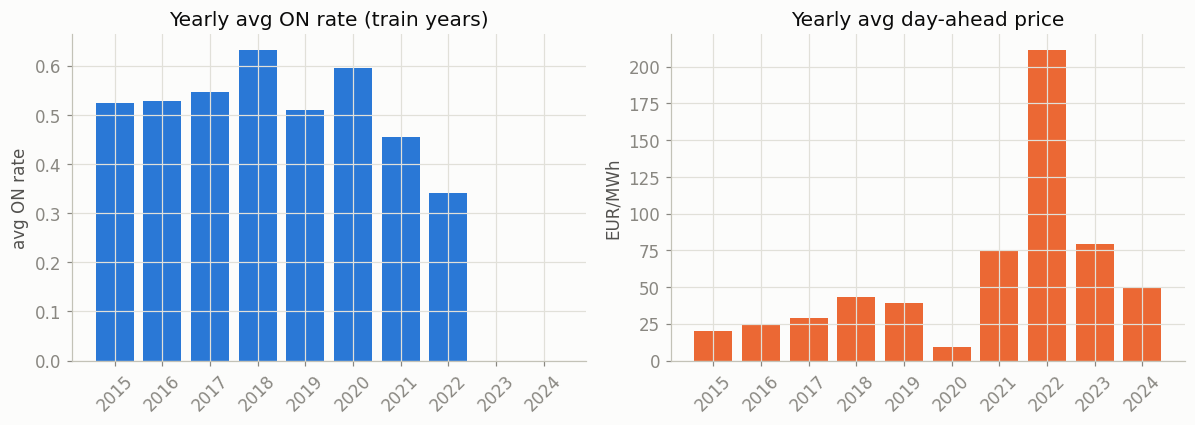

      avg_on_rate  avg_price
2015        0.524     19.822
2016        0.528     25.152
2017        0.546     28.832
2018        0.632     43.252
2019        0.510     39.264
2020        0.595      9.290
2021        0.455     75.108
2022        0.341    211.277
2023          NaN     79.439
2024          NaN     50.124


In [9]:
uc_year = uc["starttime"].dt.year
yearly_on = uc.groupby(uc_year)[label_cols].apply(lambda d: d.to_numpy().mean())
price_yearly = price[price["date"].dt.year <= 2024].groupby(price["date"].dt.year)["Day-ahead price (EUR/MWh)"].mean()

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
axes[0].bar(yearly_on.index.astype(str), yearly_on.values, color=CAT[0])
axes[0].set_title("Yearly avg ON rate (train years)")
axes[0].set_ylabel("avg ON rate")

axes[1].bar(price_yearly.index.astype(str), price_yearly.values, color=CAT[1])
axes[1].set_title("Yearly avg day-ahead price")
axes[1].set_ylabel("EUR/MWh")
for ax in axes:
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

print(pd.DataFrame({"avg_on_rate": yearly_on, "avg_price": price_yearly}).round(3))


**Insight — counterintuitive price/ON relationship, and a distribution-shift warning.** 2022 was
the European energy-crisis year: average price **more than quadrupled** (75 → 211 EUR/MWh vs.
2021), yet the average ON rate **fell to its lowest point in the series (0.34)**. The naive "high
price → turn units on" intuition doesn't hold at the year level. See §4 for why, and note that
2023–2024 (the *test* period, prices ~50–80 EUR/MWh) look more like 2018–2021 than the 2022
extreme — a model that overfits to 2022's regime could generalize poorly to the test set, so a
chronological validation split (not random shuffling) is important.


## 3. The driving inputs: price, inflow, storage, water value

Quick look at each core feature before relating them to the target.


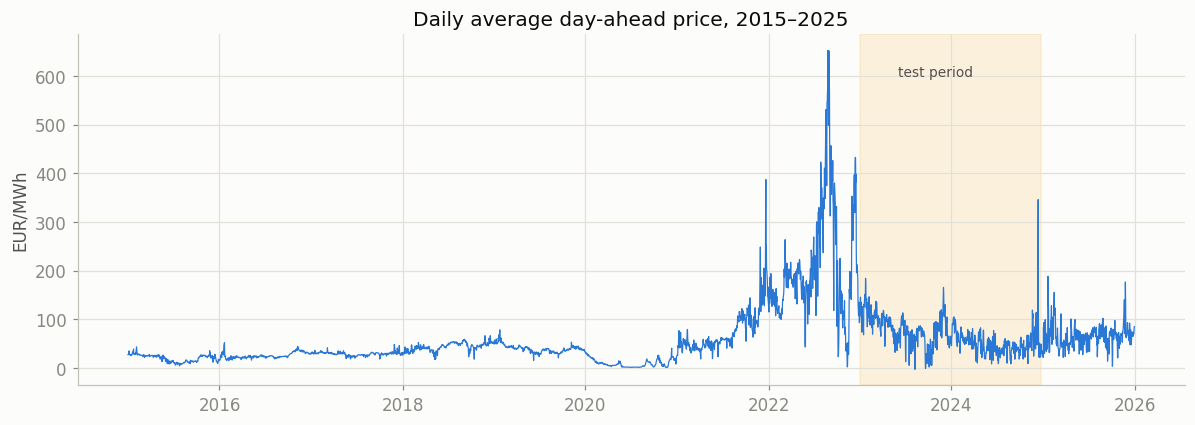

In [10]:
fig, ax = plt.subplots(figsize=(11, 4))
p_daily = price.set_index("date")["Day-ahead price (EUR/MWh)"].resample("D").mean()
ax.plot(p_daily.index, p_daily.values, color=CAT[0], lw=0.8)
ax.set_title("Daily average day-ahead price, 2015–2025")
ax.set_ylabel("EUR/MWh")
ax.axvspan(pd.Timestamp("2023-01-01"), pd.Timestamp("2024-12-25"), color=CAT[3], alpha=0.12)
ax.text(pd.Timestamp("2023-06-01"), p_daily.max()*0.92, "test period", color=INK_SECONDARY, fontsize=9)
plt.tight_layout()
plt.show()


The 2021–2022 spike (European gas/energy crisis) towers over the rest of the series and sits
entirely inside the *training* window; the shaded test period (2023–2024) is elevated relative to
2015–2020 but well below the 2022 peak. Any price-level feature should probably be normalized in
a way that's robust to this regime change (e.g. rolling/within-week statistics, log scale, or
year-relative percentile) rather than used as a raw absolute level.


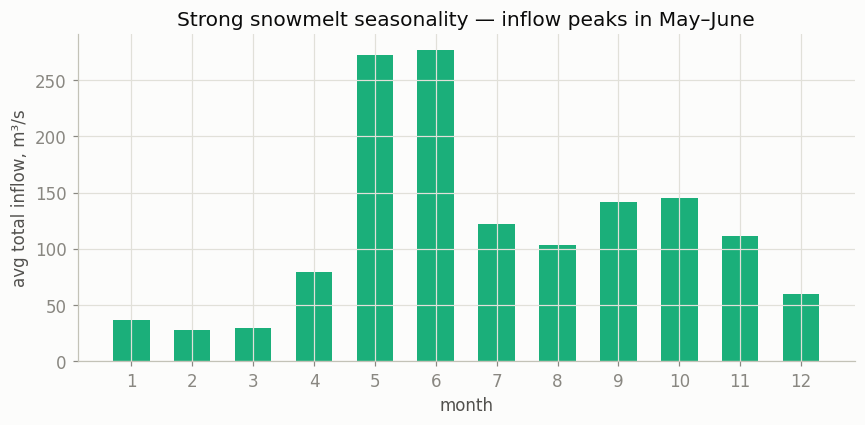

In [11]:
reservoir_cols = [c for c in inflow.columns if c not in ("date", "r_Vest_Vassdraget")]
inflow_train = inflow[(inflow["date"] >= "2015-01-01") & (inflow["date"] < "2023-01-01")].copy()
inflow_train["total"] = inflow_train[reservoir_cols].sum(axis=1)
monthly_inflow = inflow_train.groupby(inflow_train["date"].dt.month)["total"].mean()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(monthly_inflow.index, monthly_inflow.values, color=CAT[2], width=0.6)
ax.set_xticks(range(1, 13))
ax.set_xlabel("month")
ax.set_ylabel("avg total inflow, m³/s")
ax.set_title("Strong snowmelt seasonality — inflow peaks in May–June")
plt.tight_layout()
plt.show()


**Insight.** Total inflow across all 17 reservoirs is ~8x higher in May–June (snowmelt, ~270 m³/s)
than in the winter trough (Jan–Feb, ~28–37 m³/s) — textbook Norwegian hydrology. This seasonal
cycle is the physical driver behind reservoir storage and water-value seasonality below, and
`month_of_year` / `day_of_year` are likely useful features (or a sin/cos encoding of day-of-year)
even without explicit inflow data at prediction time.


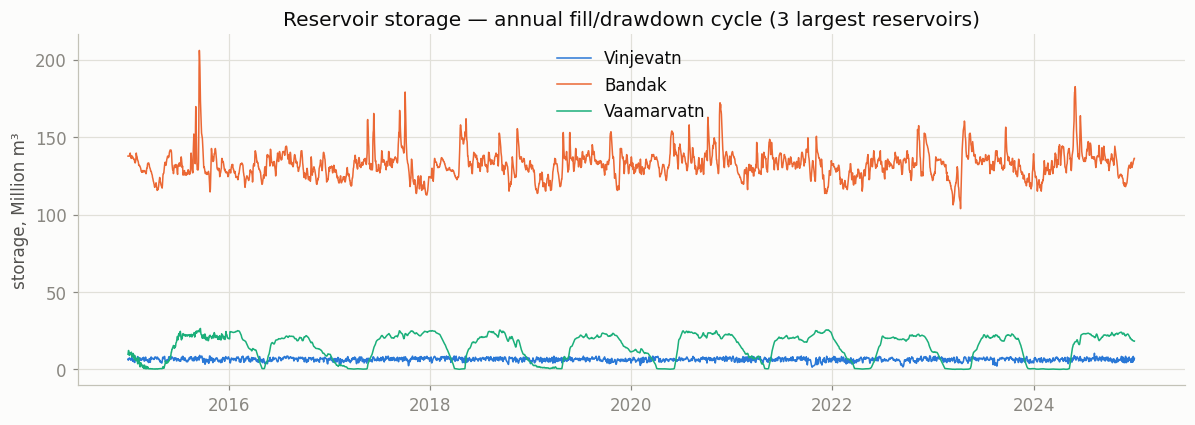

In [12]:
fig, ax = plt.subplots(figsize=(11, 4))
for i, r in enumerate(["Vinjevatn", "Bandak", "Vaamarvatn"]):
    ax.plot(volume["date"], volume[r], label=r, color=CAT[i], lw=1)
ax.set_ylabel("storage, Million m³")
ax.set_title("Reservoir storage — annual fill/drawdown cycle (3 largest reservoirs)")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()


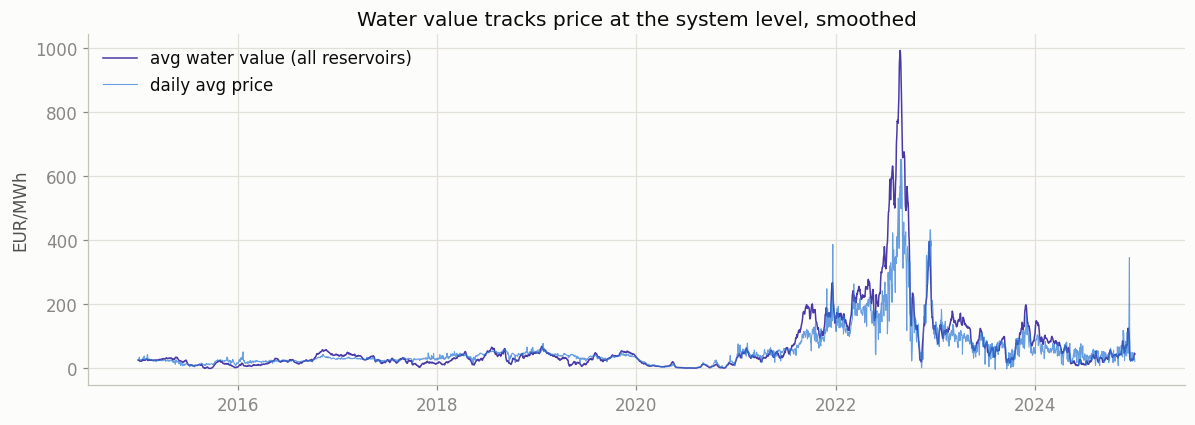

corr(avg water value, daily price): 0.937


In [13]:
fig, ax = plt.subplots(figsize=(11, 4))
wv_daily_mean = water_value.set_index("date")[[c for c in water_value.columns if c != "date"]].mean(axis=1)
ax.plot(wv_daily_mean.index, wv_daily_mean.values, color=CAT[6], lw=1, label="avg water value (all reservoirs)")
ax.plot(wv_daily_mean.index, p_daily.reindex(wv_daily_mean.index).values, color=CAT[0], lw=0.7, alpha=0.7, label="daily avg price")
ax.set_ylabel("EUR/MWh")
ax.set_title("Water value tracks price at the system level, smoothed")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

print("corr(avg water value, daily price):",
      wv_daily_mean.corr(p_daily.reindex(wv_daily_mean.index)).round(3))


**Insight.** System-average water value broadly tracks price (correlation printed above) but is
much smoother — it reflects the *expected future* value of stored water, not the instantaneous
spot price. That gap between "what I'd get if I sell now" (price) and "what this water is worth
if I save it" (water value) is exactly the economic signal a unit-commitment optimizer reacts to,
which motivates §4 below.


## 4. Relating price to ON/OFF — the key modeling insight

Naively, higher price should mean more generation. But §2 already showed the *opposite* at the
yearly level. Let's check it at the hourly level directly, and then test a more nuanced
hypothesis: **it's not the absolute price that matters, it's the price relative to the rest of
that case's 168-hour window** (i.e. "is this hour relatively expensive within its own scheduling
horizon?").


In [14]:
# Build a continuous hourly price array covering the full label horizon (with 1 week of buffer)
p_hourly = price.set_index("date")["Day-ahead price (EUR/MWh)"].sort_index()
p_hourly = p_hourly.loc["2015-01-01":"2023-01-10"]
full_idx = pd.date_range(p_hourly.index.min(), p_hourly.index.max(), freq="h")
p_hourly = p_hourly.reindex(full_idx).interpolate()
arr = p_hourly.to_numpy()
base = full_idx[0]

pos = ((uc["starttime"] - base) / pd.Timedelta(hours=1)).astype(int).to_numpy()
price_windows = np.stack([arr[p:p + 168] for p in pos])  # n_cases x 168
within_week_z = (price_windows - price_windows.mean(axis=1, keepdims=True)) / price_windows.std(axis=1, keepdims=True)

rows = []
for u in units:
    on = uc[unit_cols(u)].to_numpy()
    rows.append({
        "unit": u,
        "corr(raw price, ON)": np.corrcoef(price_windows.ravel(), on.ravel())[0, 1],
        "corr(within-week price z-score, ON)": np.corrcoef(within_week_z.ravel(), on.ravel())[0, 1],
    })
price_corr = pd.DataFrame(rows).set_index("unit").sort_values("corr(within-week price z-score, ON)", ascending=False)
price_corr.round(3)


,"corr(raw price, ON)","corr(within-week price z-score, ON)"
unit,,
Tokke_G1,-0.174,0.247
Vinje_G2,-0.071,0.217
Vinje_G3,-0.021,0.215
Vinje_G1,-0.087,0.213
Tokke_G3,-0.121,0.196
Kjela_G1,0.015,0.173
Songa_G1,-0.235,0.170
Tokke_G4,-0.100,0.167
Tokke_G2,-0.096,0.159


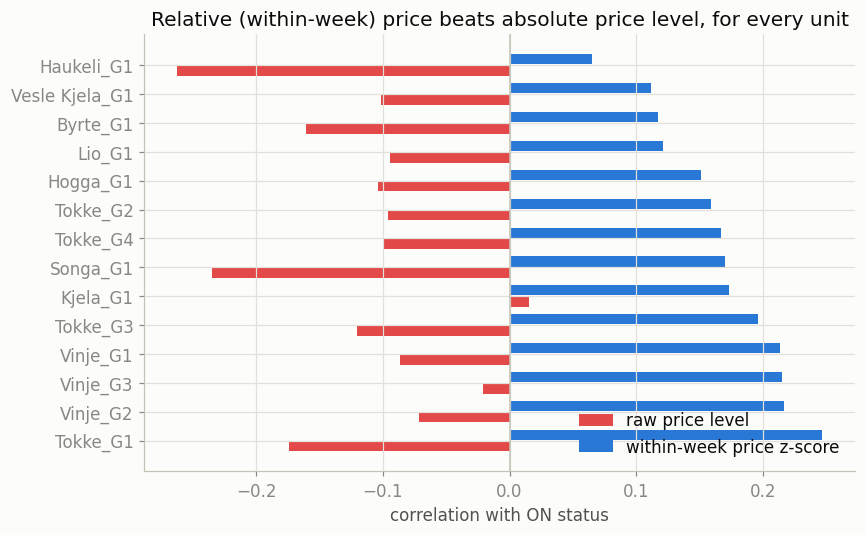

In [15]:
fig, ax = plt.subplots(figsize=(8, 5))
y = np.arange(len(price_corr))
ax.barh(y - 0.2, price_corr["corr(raw price, ON)"], height=0.35, color=CAT[7], label="raw price level")
ax.barh(y + 0.2, price_corr["corr(within-week price z-score, ON)"], height=0.35, color=CAT[0], label="within-week price z-score")
ax.axvline(0, color=BASELINE, lw=1)
ax.set_yticks(y, price_corr.index)
ax.set_xlabel("correlation with ON status")
ax.set_title("Relative (within-week) price beats absolute price level, for every unit")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()


**This is the headline finding.** For *every single unit*, correlation with ON status flips from
weak/negative using the **raw price level** to consistently **positive (~0.15–0.25)** using the
**within-week normalized price** (how expensive is this hour relative to the rest of its own
168-hour case). The optimizer isn't reacting to "is electricity expensive in absolute terms" —
it's reacting to "is *this hour* a relatively good time to sell, within the water and price
outlook of *this* week." High-price years like 2022 also tend to be scarce-water years, where the
optimizer conserves water and runs fewer units despite high prices — which is why the year-level
correlation in §2 was negative.

**Implication for feature engineering:** don't feed raw price/water-value levels alone. Build
features like:
- price percentile / z-score *within the case's own 168-hour window*
- `price − water_value` spread (the classic hydropower "sell now vs. save" signal)
- price rank relative to the case's own inflow/storage state

These relative features are very likely to carry more predictive signal than absolute levels,
and they're also more robust to the 2022-style regime shift noted in §2–3.


## 5. Extended dataset: topology and environmental constraints

`Tokke_Vinje_topology.yaml` lets us map each plant to its immediate upstream reservoir — useful
for building plant-specific (rather than system-wide) water-value / storage / inflow features.


In [16]:
import yaml

with open(f"{DATA}/extended/Tokke_Vinje_topology.yaml") as f:
    topo = yaml.safe_load(f)

plant_to_reservoir = {c["from"]: c["to"] for c in topo["connections"]
                       if c["to_type"] == "plant" and c["from_type"] == "reservoir"}
pd.Series(plant_to_reservoir, name="upstream_reservoir").rename_axis("plant")


plant
Bandak                 Hogga
Vinjevatn              Tokke
Byrtevatn                Lio
Botnedalsvatn          Byrte
Vaamarvatn             Vinje
Vatjern              Haukeli
Foersvatn              Kjela
Kjelavatn        Vesle Kjela
Name: upstream_reservoir, dtype: object

In [17]:
nonzero_min_vol = (min_volume.drop(columns="date") > 0).any()
nonzero_min_flow = (min_flow.drop(columns="date") > 0).any()
print("Reservoirs with an active minimum-volume constraint at some point:",
      nonzero_min_vol[nonzero_min_vol].index.tolist())
print("Rivers with an active minimum-flow constraint at some point:",
      nonzero_min_flow[nonzero_min_flow].index.tolist())

active_frac_vol = (min_volume.drop(columns="date") > 0).mean()
active_frac_flow = (min_flow.drop(columns="date") > 0).mean()
print("\nFraction of hours each constraint is actually binding (>0):")
print(active_frac_vol[active_frac_vol > 0].round(3))
print(active_frac_flow[active_frac_flow > 0].round(3))


Reservoirs with an active minimum-volume constraint at some point: ['Totak', 'Byrtevatn', 'Staavatn']
Rivers with an active minimum-flow constraint at some point: ['b_Kjelavatn', 'b_Hyljelihyl', 'b_Vinjevatn', 'b_Byrtevatn', 'b_Bandak', 'r_Vest_Vassdraget']

Fraction of hours each constraint is actually binding (>0):
Totak        0.339
Byrtevatn    0.126
Staavatn     0.255
dtype: float64
b_Kjelavatn          1.000
b_Hyljelihyl         1.000
b_Vinjevatn          1.000
b_Byrtevatn          0.339
b_Bandak             1.000
r_Vest_Vassdraget    1.000
dtype: float64


**Insight.** Environmental constraints are sparse and seasonal (only a handful of reservoirs/rivers
are ever constrained, and only part of the year) — they're a minority-class "regime" feature
rather than a continuous one: worth encoding as a binary "is this reservoir/river currently
constrained" flag per case/hour rather than feeding the raw (mostly-zero) values directly.


## 6. Summary of findings to carry into modeling

1. **Clean data.** No missing values in any core or extended file; date ranges and reservoir
   names are consistent across files; `min_volume`/`min_flow` reservoirs/rivers are a strict
   subset of the full 17.
2. **`total_calculation_time` is leakage** — solver metadata not available at test time. Exclude
   it from any feature pipeline.
3. **Per-unit class imbalance** ranges from 26% to 75% ON — validate and threshold per unit, not
   just on the pooled micro-AUC.
4. **Units are strongly correlated**, both within a plant (0.8–0.96) and even across plants
   (Tokke↔Vinje ~0.8–0.9) — favors a joint / multi-label model over 14 independent models.
5. **Strong intraday seasonality, weak weekly seasonality** — `hour_of_day` (and its position
   within the 168-hour case) is a much more informative time feature than `day_of_week`.
6. **Strong annual seasonality in inflow and storage** (snowmelt-driven) — `day_of_year` /
   month is a useful feature even without live inflow data.
7. **Absolute price/water-value level is a weak, sometimes-negative predictor; relative price
   *within the case's own week* is a consistently positive predictor for every unit.** Build
   within-case normalized price features and `price − water_value` spreads rather than relying on
   raw levels.
8. **2022 is a regime outlier** (extreme prices, lowest ON rate in the series) that sits in the
   training data but not in the 2023–2024 test period — use a chronological validation split and
   check robustness to that year specifically, rather than a random split.
9. **Topology data lets us build plant-specific features** (each plant's own upstream reservoir's
   storage/water value/inflow) rather than only system-wide aggregates, and environmental
   constraints are sparse enough to encode as binary flags.
